<a href="https://colab.research.google.com/github/kumarsaurabh1817/Final-Computer-Vision-Training/blob/main/week2_classification/day5_ablation_evaluation/Week2_Day5_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 2 · Day 5 — Final Ablation & Error Analysis

This Colab notebook completes the Week 2 deliverable on the **Intel Image Classification** dataset. It runs three reproducible experiments:

1. `scratch_no_aug` — ResNet-18 trained from random initialization (training-from-scratch reference)
2. `pretrained_no_aug` — ImageNet-pretrained ResNet-18, no random augmentation (control)
3. `pretrained_aug` — the same pretrained model and hyperparameters, with label-preserving augmentation

Only experiments 2 and 3 form the **controlled augmentation ablation**. Experiment 1 answers the separate transfer-learning question. The notebook creates an ablation table, learning curves, confusion matrices, per-class precision/recall/F1, machine-readable results, and a final Markdown report.

> Runtime: select **Runtime → Change runtime type → T4 GPU** before starting. Run all cells in order.

## 0 · Install dependencies and verify the GPU

The public dataset is downloaded automatically with `kagglehub`; no Kaggle API token is normally required. Internet access is required once for the dataset and pretrained weights.

In [1]:
!pip install -q "albumentations>=2.0.0" "scikit-learn>=1.4.0" kagglehub seaborn

import torch
print(f'PyTorch: {torch.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')
if not torch.cuda.is_available():
    print('WARNING: enable a T4 GPU; CPU training will be very slow.')
else:
    print(f'GPU: {torch.cuda.get_device_name(0)}')

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


## 1 · Configuration and reproducibility

`FULL_RUN=True` is the deliverable run. Set it to `False` only for a quick end-to-end smoke test. Results from quick mode must not be presented as final metrics.

In [2]:
from pathlib import Path
from dataclasses import dataclass, asdict
from copy import deepcopy
import gc, json, random, time

import albumentations as A
from albumentations.pytorch import ToTensorV2
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision.datasets import ImageFolder
from torchvision.models import ResNet18_Weights, resnet18

FULL_RUN = True
SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 64 if torch.cuda.is_available() else 16
EPOCHS = 10 if FULL_RUN else 1
NUM_WORKERS = 2
VAL_FRACTION = 0.15
PATIENCE = 3 if FULL_RUN else 1
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUTPUT_DIR = Path('/content/week2_day5_outputs')
MODEL_DIR = OUTPUT_DIR / 'models'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

seed_everything()
print({'device': str(DEVICE), 'full_run': FULL_RUN, 'epochs': EPOCHS, 'batch_size': BATCH_SIZE})

{'device': 'cuda', 'full_run': True, 'epochs': 10, 'batch_size': 64}


## 2 · Download and validate the dataset

Expected classes: `buildings`, `forest`, `glacier`, `mountain`, `sea`, and `street`. The official test folders remain untouched until final evaluation; validation is stratified from the training folders.

In [3]:
dataset_root = Path(kagglehub.dataset_download('puneet6060/intel-image-classification'))
print(f'Dataset cache: {dataset_root}')

def locate_split(root, split_name):
    expected = {'buildings', 'forest', 'glacier', 'mountain', 'sea', 'street'}
    for candidate in [root / split_name / split_name, root / split_name, *root.rglob(split_name)]:
        if candidate.is_dir():
            child_dirs = {p.name for p in candidate.iterdir() if p.is_dir()}
            if expected.issubset(child_dirs):
                return candidate
    raise FileNotFoundError(f'Could not locate {split_name} below {root}')

train_dir = locate_split(dataset_root, 'seg_train')
test_dir = locate_split(dataset_root, 'seg_test')
raw_train = ImageFolder(str(train_dir))
raw_test = ImageFolder(str(test_dir))
assert raw_train.classes == raw_test.classes, 'Train/test class mappings differ.'
class_names = raw_train.classes
num_classes = len(class_names)

all_indices = np.arange(len(raw_train))
all_targets = np.asarray(raw_train.targets)
train_indices, val_indices = train_test_split(
    all_indices, test_size=VAL_FRACTION, random_state=SEED,
    stratify=all_targets
)
if not FULL_RUN:
    def stratified_subset(indices, targets, per_class):
        rng = np.random.default_rng(SEED)
        parts = []
        for class_id in range(num_classes):
            choices = indices[targets[indices] == class_id]
            parts.extend(rng.choice(choices, min(per_class, len(choices)), replace=False))
        return np.asarray(parts)
    train_indices = stratified_subset(train_indices, all_targets, 80)
    val_indices = stratified_subset(val_indices, all_targets, 30)
    test_indices = stratified_subset(np.arange(len(raw_test)), np.asarray(raw_test.targets), 30)
else:
    test_indices = np.arange(len(raw_test))

print(f'Classes ({num_classes}): {class_names}')
print(f'Train: {len(train_indices):,} | Validation: {len(val_indices):,} | Test: {len(test_indices):,}')

Using Colab cache for faster access to the 'intel-image-classification' dataset.
Dataset cache: /kaggle/input/intel-image-classification
Classes (6): ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Train: 11,928 | Validation: 2,106 | Test: 3,000


## 3 · Deterministic evaluation and two training pipelines

Validation/test use only resize, center crop, normalization, and tensor conversion. The augmentation treatment uses realistic horizontal flips, small affine changes, color/lighting variation, mild blur/noise, and coarse dropout. Vertical flips are intentionally excluded because they violate outdoor-scene geometry.

In [4]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

no_aug_transform = A.Compose([
    A.Resize(256, 256), A.CenterCrop(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD), ToTensorV2(),
])
aug_transform = A.Compose([
    A.Resize(256, 256), A.RandomResizedCrop(size=(IMG_SIZE, IMG_SIZE), scale=(0.75, 1.0), ratio=(0.9, 1.1), p=1.0),
    A.HorizontalFlip(p=0.5),
    A.Affine(scale=(0.9, 1.1), translate_percent=(-0.05, 0.05), rotate=(-15, 15), shear=(-5, 5), p=0.5),
    A.OneOf([A.RandomBrightnessContrast(0.2, 0.2), A.HueSaturationValue(10, 15, 10)], p=0.5),
    A.OneOf([A.GaussianBlur(blur_limit=(3, 5)), A.GaussNoise(std_range=(0.01, 0.04))], p=0.2),
    A.CoarseDropout(num_holes_range=(1, 4), hole_height_range=(0.05, 0.15), hole_width_range=(0.05, 0.15), fill='random_uniform', p=0.25),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD), ToTensorV2(),
])

class IndexedAlbumentationsDataset(Dataset):
    def __init__(self, folder_dataset, indices, transform):
        self.samples = [folder_dataset.samples[int(i)] for i in indices]
        self.transform = transform
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, index):
        path, label = self.samples[index]
        with Image.open(path) as image:
            image = np.asarray(image.convert('RGB'))
        return self.transform(image=image)['image'], label

def make_loaders(train_transform):
    # Albumentations owns an internal RNG; seed each fresh experiment explicitly.
    train_transform.set_random_seed(SEED)
    no_aug_transform.set_random_seed(SEED)
    datasets = {
        'train': IndexedAlbumentationsDataset(raw_train, train_indices, train_transform),
        'val': IndexedAlbumentationsDataset(raw_train, val_indices, no_aug_transform),
        'test': IndexedAlbumentationsDataset(raw_test, test_indices, no_aug_transform),
    }
    generator = torch.Generator().manual_seed(SEED)
    common = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
                  pin_memory=torch.cuda.is_available(), worker_init_fn=seed_worker,
                  persistent_workers=NUM_WORKERS > 0)
    return {
        'train': DataLoader(datasets['train'], shuffle=True, generator=generator, **common),
        'val': DataLoader(datasets['val'], shuffle=False, **common),
        'test': DataLoader(datasets['test'], shuffle=False, **common),
    }

# Sanity check shapes and labels before expensive training.
sample_loader = make_loaders(aug_transform)['train']
images, labels = next(iter(sample_loader))
assert images.shape[1:] == (3, IMG_SIZE, IMG_SIZE)
assert labels.min() >= 0 and labels.max() < num_classes
print(f'Sanity check passed: images={tuple(images.shape)}, labels={tuple(labels.shape)}')
del sample_loader, images, labels

Sanity check passed: images=(64, 3, 224, 224), labels=(64,)


## 4 · Model, training loop, and evaluation

Pretrained runs use a 100× smaller learning rate for the backbone than for the new classifier head. The scratch run uses one learning rate because every layer starts untrained. Early stopping selects the best validation checkpoint; the test set is evaluated exactly once per selected checkpoint.

In [5]:
@dataclass(frozen=True)
class Experiment:
    name: str
    pretrained: bool
    augmented: bool
    head_lr: float
    backbone_lr: float

EXPERIMENTS = [
    Experiment('scratch_no_aug', False, False, 1e-3, 1e-3),
    Experiment('pretrained_no_aug', True, False, 1e-3, 1e-5),
    Experiment('pretrained_aug', True, True, 1e-3, 1e-5),
]

def build_model(pretrained):
    model = resnet18(weights=ResNet18_Weights.DEFAULT if pretrained else None)
    in_features = model.fc.in_features
    model.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(in_features, num_classes))
    return model.to(DEVICE)

def make_optimizer(model, exp):
    if not exp.pretrained:
        return optim.AdamW(model.parameters(), lr=exp.head_lr, weight_decay=1e-4)
    head_ids = {id(p) for p in model.fc.parameters()}
    backbone = [p for p in model.parameters() if id(p) not in head_ids]
    return optim.AdamW([
        {'params': backbone, 'lr': exp.backbone_lr},
        {'params': model.fc.parameters(), 'lr': exp.head_lr},
    ], weight_decay=1e-4)

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss = total_correct = total = 0
    predictions, targets = [], []
    context = torch.enable_grad() if training else torch.inference_mode()
    with context:
        for batch_images, batch_targets in loader:
            batch_images = batch_images.to(DEVICE, non_blocking=True)
            batch_targets = batch_targets.to(DEVICE, non_blocking=True)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(batch_images)
            loss = criterion(logits, batch_targets)
            if training:
                loss.backward()
                optimizer.step()
            batch_preds = logits.argmax(1)
            total_loss += loss.item() * len(batch_targets)
            total_correct += (batch_preds == batch_targets).sum().item()
            total += len(batch_targets)
            if not training:
                predictions.extend(batch_preds.cpu().tolist())
                targets.extend(batch_targets.cpu().tolist())
    return {
        'loss': total_loss / total, 'accuracy': total_correct / total,
        'predictions': predictions, 'targets': targets,
    }

def train_experiment(exp):
    seed_everything()  # identical initialization/dropout/order where applicable
    loaders = make_loaders(aug_transform if exp.augmented else no_aug_transform)
    model = build_model(exp.pretrained)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = make_optimizer(model, exp)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
    history = {'train_loss': [], 'train_accuracy': [], 'val_loss': [], 'val_accuracy': []}
    best_val_accuracy, stale_epochs = -1.0, 0
    checkpoint = MODEL_DIR / f'{exp.name}.pt'
    started = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        train_metrics = run_epoch(model, loaders['train'], criterion, optimizer)
        val_metrics = run_epoch(model, loaders['val'], criterion)
        scheduler.step()
        for split, metrics in [('train', train_metrics), ('val', val_metrics)]:
            history[f'{split}_loss'].append(metrics['loss'])
            history[f'{split}_accuracy'].append(metrics['accuracy'])
        print(f'{exp.name:20s} epoch {epoch:02d}/{EPOCHS} | '
              f'train {train_metrics["accuracy"]:.3f} | val {val_metrics["accuracy"]:.3f}')
        if val_metrics['accuracy'] > best_val_accuracy + 1e-6:
            best_val_accuracy = val_metrics['accuracy']
            stale_epochs = 0
            torch.save(model.state_dict(), checkpoint)
        else:
            stale_epochs += 1
            if stale_epochs >= PATIENCE:
                print(f'Early stopping {exp.name} at epoch {epoch}.')
                break
    model.load_state_dict(torch.load(checkpoint, map_location=DEVICE, weights_only=True))
    test_metrics = run_epoch(model, loaders['test'], criterion)
    report = classification_report(
        test_metrics['targets'], test_metrics['predictions'],
        labels=list(range(num_classes)), target_names=class_names,
        output_dict=True, zero_division=0
    )
    result = {
        **asdict(exp), 'epochs_completed': len(history['val_accuracy']),
        'best_val_accuracy': best_val_accuracy,
        'test_accuracy': test_metrics['accuracy'],
        'macro_f1': report['macro avg']['f1-score'],
        'weighted_f1': report['weighted avg']['f1-score'],
        'training_seconds': time.perf_counter() - started,
        'history': history, 'classification_report': report,
        'confusion_matrix': confusion_matrix(
            test_metrics['targets'], test_metrics['predictions'],
            labels=list(range(num_classes))
        ).tolist(),
    }
    del model, optimizer, loaders
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result

print('Experiments:', [e.name for e in EXPERIMENTS])

Experiments: ['scratch_no_aug', 'pretrained_no_aug', 'pretrained_aug']


## 5 · Run all experiments

This is the long-running cell. A T4 is strongly recommended.

In [6]:
results = []
for experiment in EXPERIMENTS:
    print('\n' + '=' * 80)
    print(f'Starting {experiment.name}')
    results.append(train_experiment(experiment))
print('\nAll experiments completed.')


Starting scratch_no_aug
scratch_no_aug       epoch 01/10 | train 0.641 | val 0.648
scratch_no_aug       epoch 02/10 | train 0.756 | val 0.776
scratch_no_aug       epoch 03/10 | train 0.801 | val 0.798
scratch_no_aug       epoch 04/10 | train 0.825 | val 0.808
scratch_no_aug       epoch 05/10 | train 0.842 | val 0.825
scratch_no_aug       epoch 06/10 | train 0.859 | val 0.826
scratch_no_aug       epoch 07/10 | train 0.880 | val 0.865
scratch_no_aug       epoch 08/10 | train 0.901 | val 0.876
scratch_no_aug       epoch 09/10 | train 0.916 | val 0.904
scratch_no_aug       epoch 10/10 | train 0.929 | val 0.896

Starting pretrained_no_aug
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 196MB/s]


pretrained_no_aug    epoch 01/10 | train 0.827 | val 0.920
pretrained_no_aug    epoch 02/10 | train 0.914 | val 0.929
pretrained_no_aug    epoch 03/10 | train 0.936 | val 0.923
pretrained_no_aug    epoch 04/10 | train 0.948 | val 0.929
pretrained_no_aug    epoch 05/10 | train 0.958 | val 0.928
Early stopping pretrained_no_aug at epoch 5.

Starting pretrained_aug
pretrained_aug       epoch 01/10 | train 0.791 | val 0.913
pretrained_aug       epoch 02/10 | train 0.886 | val 0.924
pretrained_aug       epoch 03/10 | train 0.908 | val 0.925
pretrained_aug       epoch 04/10 | train 0.915 | val 0.929
pretrained_aug       epoch 05/10 | train 0.922 | val 0.932
pretrained_aug       epoch 06/10 | train 0.925 | val 0.934
pretrained_aug       epoch 07/10 | train 0.930 | val 0.937
pretrained_aug       epoch 08/10 | train 0.935 | val 0.934
pretrained_aug       epoch 09/10 | train 0.932 | val 0.936
pretrained_aug       epoch 10/10 | train 0.932 | val 0.933
Early stopping pretrained_aug at epoch 10.

A

## 6 · Ablation table and learning curves

The augmentation effect is `pretrained_aug − pretrained_no_aug`. The transfer-learning effect is `pretrained_no_aug − scratch_no_aug`. These deltas answer different questions and are reported separately.

,experiment,pretrained,augmented,epochs,best_val_accuracy,test_accuracy,macro_f1,weighted_f1,training_minutes,delta_vs_pretrained_no_aug
0,scratch_no_aug,False,False,10,90.36%,88.80%,0.889,0.887,7.7,-3.90%
1,pretrained_no_aug,True,False,5,92.88%,92.70%,0.928,0.927,3.8,+0.00%
2,pretrained_aug,True,True,10,93.68%,93.13%,0.932,0.931,8.2,+0.43%


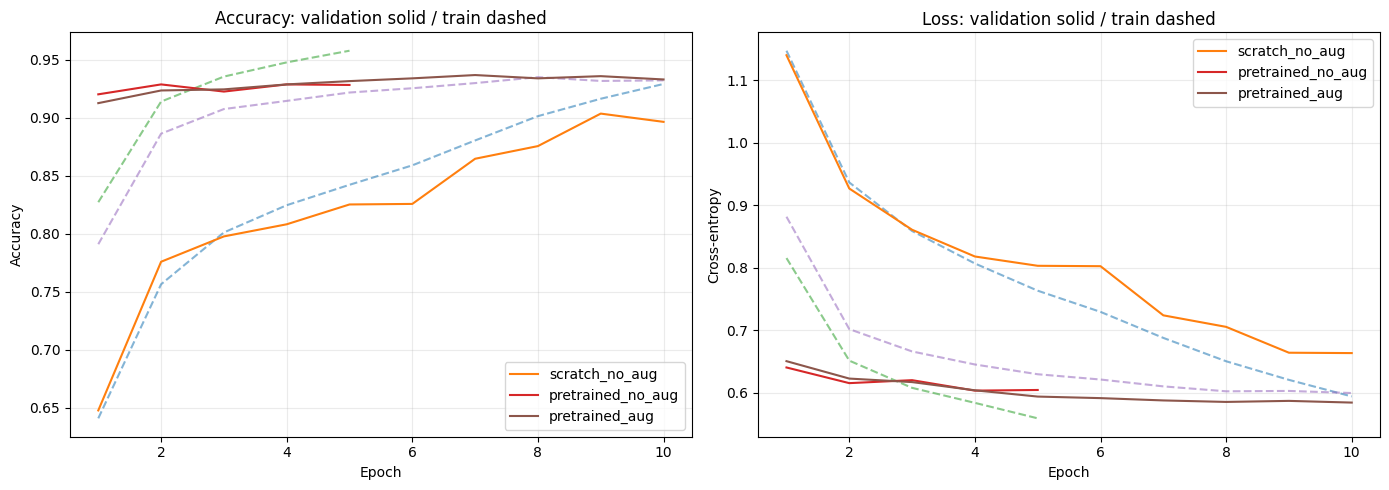

In [7]:
summary_rows = [{
    'experiment': r['name'], 'pretrained': r['pretrained'], 'augmented': r['augmented'],
    'epochs': r['epochs_completed'], 'best_val_accuracy': r['best_val_accuracy'],
    'test_accuracy': r['test_accuracy'], 'macro_f1': r['macro_f1'],
    'weighted_f1': r['weighted_f1'], 'training_minutes': r['training_seconds'] / 60,
} for r in results]
summary_df = pd.DataFrame(summary_rows)
baseline_acc = summary_df.set_index('experiment').loc['pretrained_no_aug', 'test_accuracy']
summary_df['delta_vs_pretrained_no_aug'] = summary_df['test_accuracy'] - baseline_acc
display(summary_df.style.format({
    'best_val_accuracy': '{:.2%}', 'test_accuracy': '{:.2%}', 'macro_f1': '{:.3f}',
    'weighted_f1': '{:.3f}', 'training_minutes': '{:.1f}',
    'delta_vs_pretrained_no_aug': '{:+.2%}',
}))
summary_df.to_csv(OUTPUT_DIR / 'ablation_results.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for r in results:
    x = range(1, len(r['history']['val_accuracy']) + 1)
    axes[0].plot(x, r['history']['train_accuracy'], '--', alpha=.55)
    axes[0].plot(x, r['history']['val_accuracy'], label=r['name'])
    axes[1].plot(x, r['history']['train_loss'], '--', alpha=.55)
    axes[1].plot(x, r['history']['val_loss'], label=r['name'])
axes[0].set(title='Accuracy: validation solid / train dashed', xlabel='Epoch', ylabel='Accuracy')
axes[1].set(title='Loss: validation solid / train dashed', xlabel='Epoch', ylabel='Cross-entropy')
for ax in axes:
    ax.grid(alpha=.25); ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'learning_curves.png', dpi=160, bbox_inches='tight')
plt.show()

## 7 · Confusion matrices and per-class metrics

Rows are true classes and columns are predicted classes. Row normalization answers: “Of all real examples in this class, what fraction was predicted as each class?”

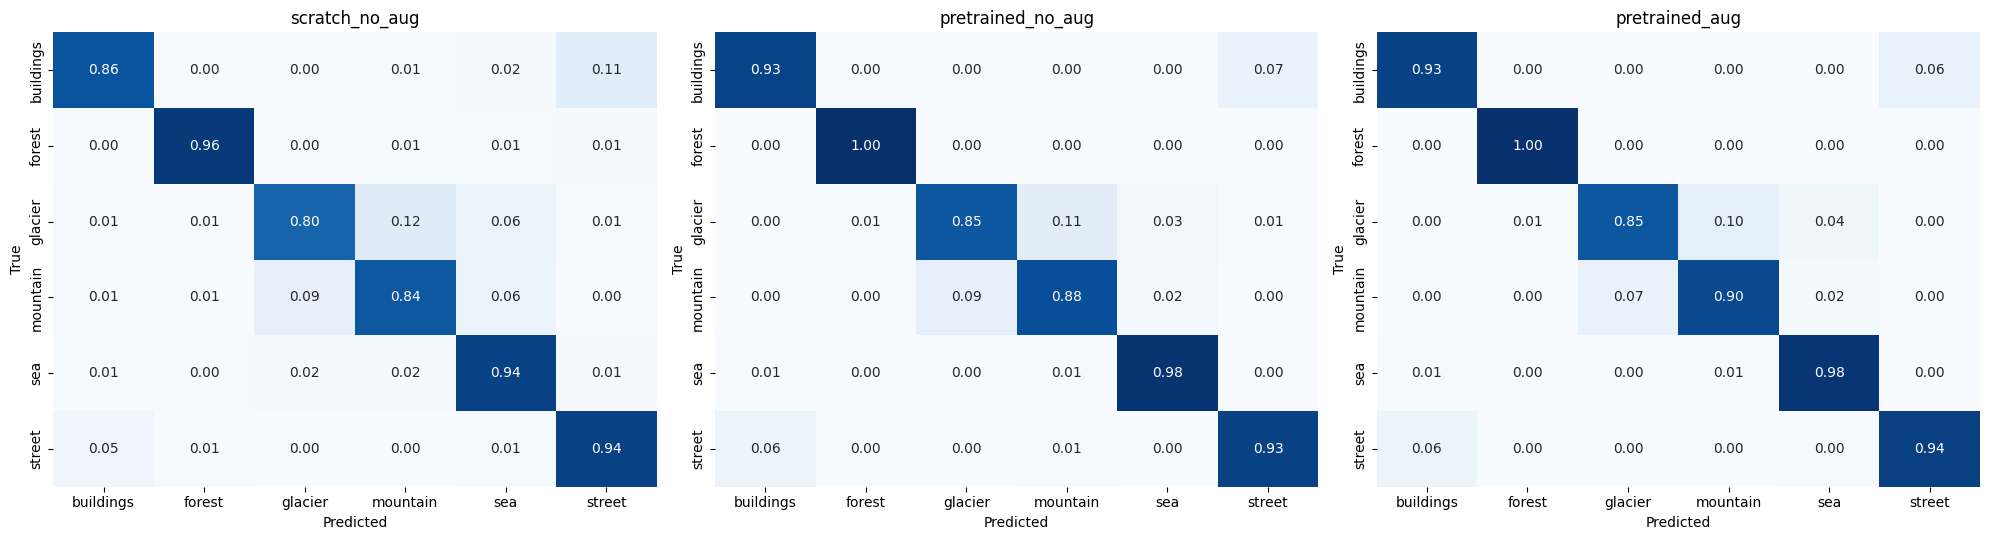

,experiment,class,precision,recall,f1-score,support
0,scratch_no_aug,buildings,0.915,0.860,0.887,437
1,scratch_no_aug,forest,0.966,0.964,0.965,474
2,scratch_no_aug,glacier,0.887,0.797,0.840,553
3,scratch_no_aug,mountain,0.841,0.844,0.842,525
4,scratch_no_aug,sea,0.860,0.937,0.897,510
5,scratch_no_aug,street,0.875,0.936,0.905,501
6,pretrained_no_aug,buildings,0.921,0.929,0.925,437
7,pretrained_no_aug,forest,0.983,0.998,0.991,474
8,pretrained_no_aug,glacier,0.912,0.848,0.879,553
9,pretrained_no_aug,mountain,0.874,0.884,0.879,525


In [8]:
fig, axes = plt.subplots(1, len(results), figsize=(20, 5.5))
per_class_frames = []
for ax, r in zip(axes, results):
    cm = np.asarray(r['confusion_matrix'])
    cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1,
                xticklabels=class_names, yticklabels=class_names, ax=ax, cbar=False)
    ax.set(title=r['name'], xlabel='Predicted', ylabel='True')
    report_df = pd.DataFrame(r['classification_report']).T.loc[class_names, ['precision', 'recall', 'f1-score', 'support']]
    report_df.insert(0, 'class', report_df.index)
    report_df.insert(0, 'experiment', r['name'])
    per_class_frames.append(report_df.reset_index(drop=True))
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'confusion_matrices_normalized.png', dpi=180, bbox_inches='tight')
plt.show()

per_class_df = pd.concat(per_class_frames, ignore_index=True)
per_class_df.to_csv(OUTPUT_DIR / 'per_class_metrics.csv', index=False)
display(per_class_df.style.format({'precision': '{:.3f}', 'recall': '{:.3f}', 'f1-score': '{:.3f}', 'support': '{:.0f}'}))

## 8 · Save results and generate the final interpretation

The write-up is generated from measured metrics; it does not claim that augmentation helped unless the run shows that it did.

In [9]:
with open(OUTPUT_DIR / 'full_results.json', 'w') as f:
    json.dump({
        'seed': SEED, 'full_run': FULL_RUN, 'epochs_requested': EPOCHS,
        'class_names': class_names, 'experiments': results,
    }, f, indent=2)

by_name = {r['name']: r for r in results}
transfer_delta = by_name['pretrained_no_aug']['test_accuracy'] - by_name['scratch_no_aug']['test_accuracy']
augmentation_delta = by_name['pretrained_aug']['test_accuracy'] - by_name['pretrained_no_aug']['test_accuracy']
aug_direction = 'improved' if augmentation_delta > 0 else ('reduced' if augmentation_delta < 0 else 'did not change')
best = max(results, key=lambda r: r['test_accuracy'])
aug_report = pd.DataFrame(by_name['pretrained_aug']['classification_report']).T.loc[class_names]
weakest_class = aug_report['f1-score'].idxmin()
strongest_class = aug_report['f1-score'].idxmax()

report = f'''# Week 2 Final Results — Image Classification & Transfer Learning

## Experimental setup

- Dataset: Intel Image Classification ({num_classes} classes)
- Backbone: ResNet-18
- Selection: best validation checkpoint; final test split evaluated after selection
- Controlled augmentation comparison: pretrained model without vs with augmentation
- Seed: {SEED}

## Main findings

- Transfer learning changed test accuracy by {transfer_delta:+.2%} compared with the from-scratch reference.
- Augmentation {aug_direction} test accuracy by {augmentation_delta:+.2%} against the pretrained no-augmentation control.
- Best configuration: `{best['name']}` at {best['test_accuracy']:.2%} test accuracy and {best['macro_f1']:.3f} macro F1.
- Under the augmented model, `{strongest_class}` had the strongest F1 and `{weakest_class}` had the weakest F1; inspect the confusion matrix for the dominant error pair.

## Interpretation

The transfer-learning and augmentation deltas answer different questions. The former changes initialization; the latter keeps initialization, split, model, optimizer, learning rates, epoch budget, and evaluation pipeline fixed while changing only training-time augmentation. A negative augmentation delta is still a valid result and suggests that the chosen policy may be too strong, mismatched to the domain, or need a longer training budget.

## Artifacts

- `ablation_results.csv` — experiment-level metrics and deltas
- `per_class_metrics.csv` — precision, recall, F1, and support
- `confusion_matrices_normalized.png` — class error patterns
- `learning_curves.png` — train/validation behavior
- `full_results.json` — complete metrics and histories
- `models/*.pt` — best validation checkpoint from each run
'''
(OUTPUT_DIR / 'final_results.md').write_text(report, encoding='utf-8')
print(report)
print(f'All artifacts saved under: {OUTPUT_DIR}')

# Week 2 Final Results — Image Classification & Transfer Learning

## Experimental setup

- Dataset: Intel Image Classification (6 classes)
- Backbone: ResNet-18
- Selection: best validation checkpoint; final test split evaluated after selection
- Controlled augmentation comparison: pretrained model without vs with augmentation
- Seed: 42

## Main findings

- Transfer learning changed test accuracy by +3.90% compared with the from-scratch reference.
- Augmentation improved test accuracy by +0.43% against the pretrained no-augmentation control.
- Best configuration: `pretrained_aug` at 93.13% test accuracy and 0.932 macro F1.
- Under the augmented model, `forest` had the strongest F1 and `glacier` had the weakest F1; inspect the confusion matrix for the dominant error pair.

## Interpretation

The transfer-learning and augmentation deltas answer different questions. The former changes initialization; the latter keeps initialization, split, model, optimizer, learning rates, epoch budget,

## 9 · Download the artifacts

This creates one ZIP containing the report, plots, tables, JSON, and checkpoints. Download it before the Colab runtime disconnects.

In [10]:
import shutil
archive = shutil.make_archive('/content/week2_day5_outputs', 'zip', OUTPUT_DIR)
print(f'Created: {archive}')
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print('Not running in Colab; download the ZIP manually.')

Created: /content/week2_day5_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Completion checklist

- [ ] Notebook run in **full mode** (`FULL_RUN=True`) on a GPU
- [ ] `pretrained_no_aug` and `pretrained_aug` both completed
- [ ] Ablation delta interpreted by its sign, without assuming augmentation must help
- [ ] Confusion matrices and per-class metrics inspected
- [ ] ZIP downloaded before the Colab session expired
- [ ] Measured results copied into the repository README / final write-up

Week 2’s success gate is met only if your measured fine-tuned model clearly beats the scratch reference and the augmentation effect is reported accurately (positive or negative).